**Course outline:** Unit 02 · Notebook 01 · Python

# Trace Laila's reporting pathways

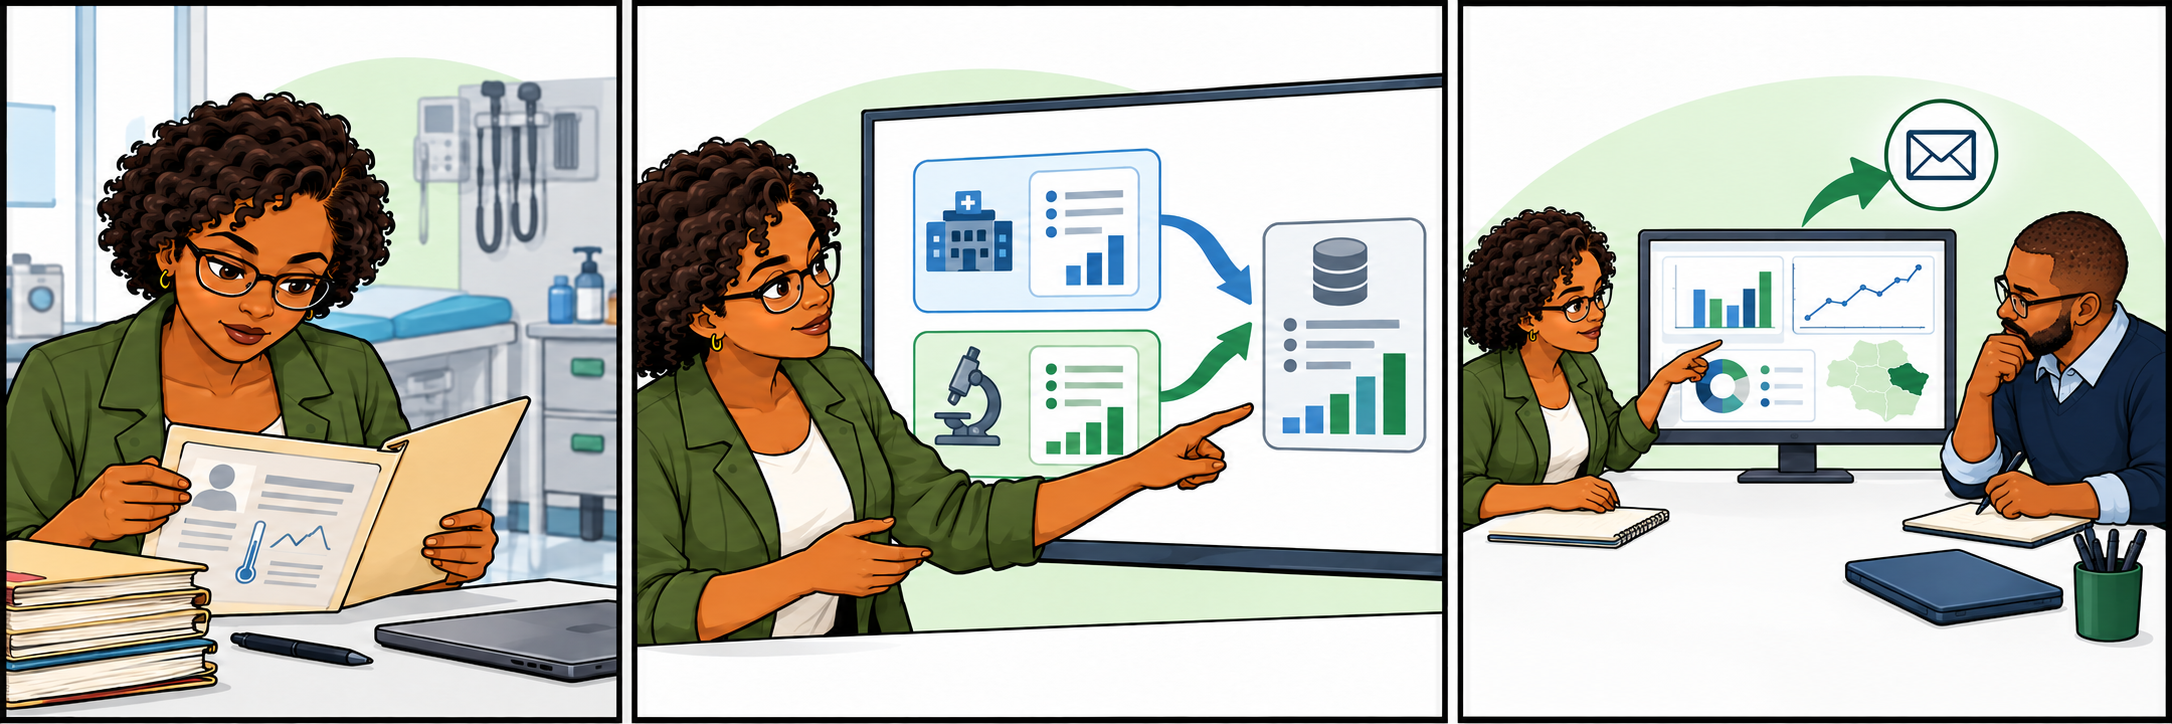

*Laila needs to know where a report begins and which systems carry it to the district.*

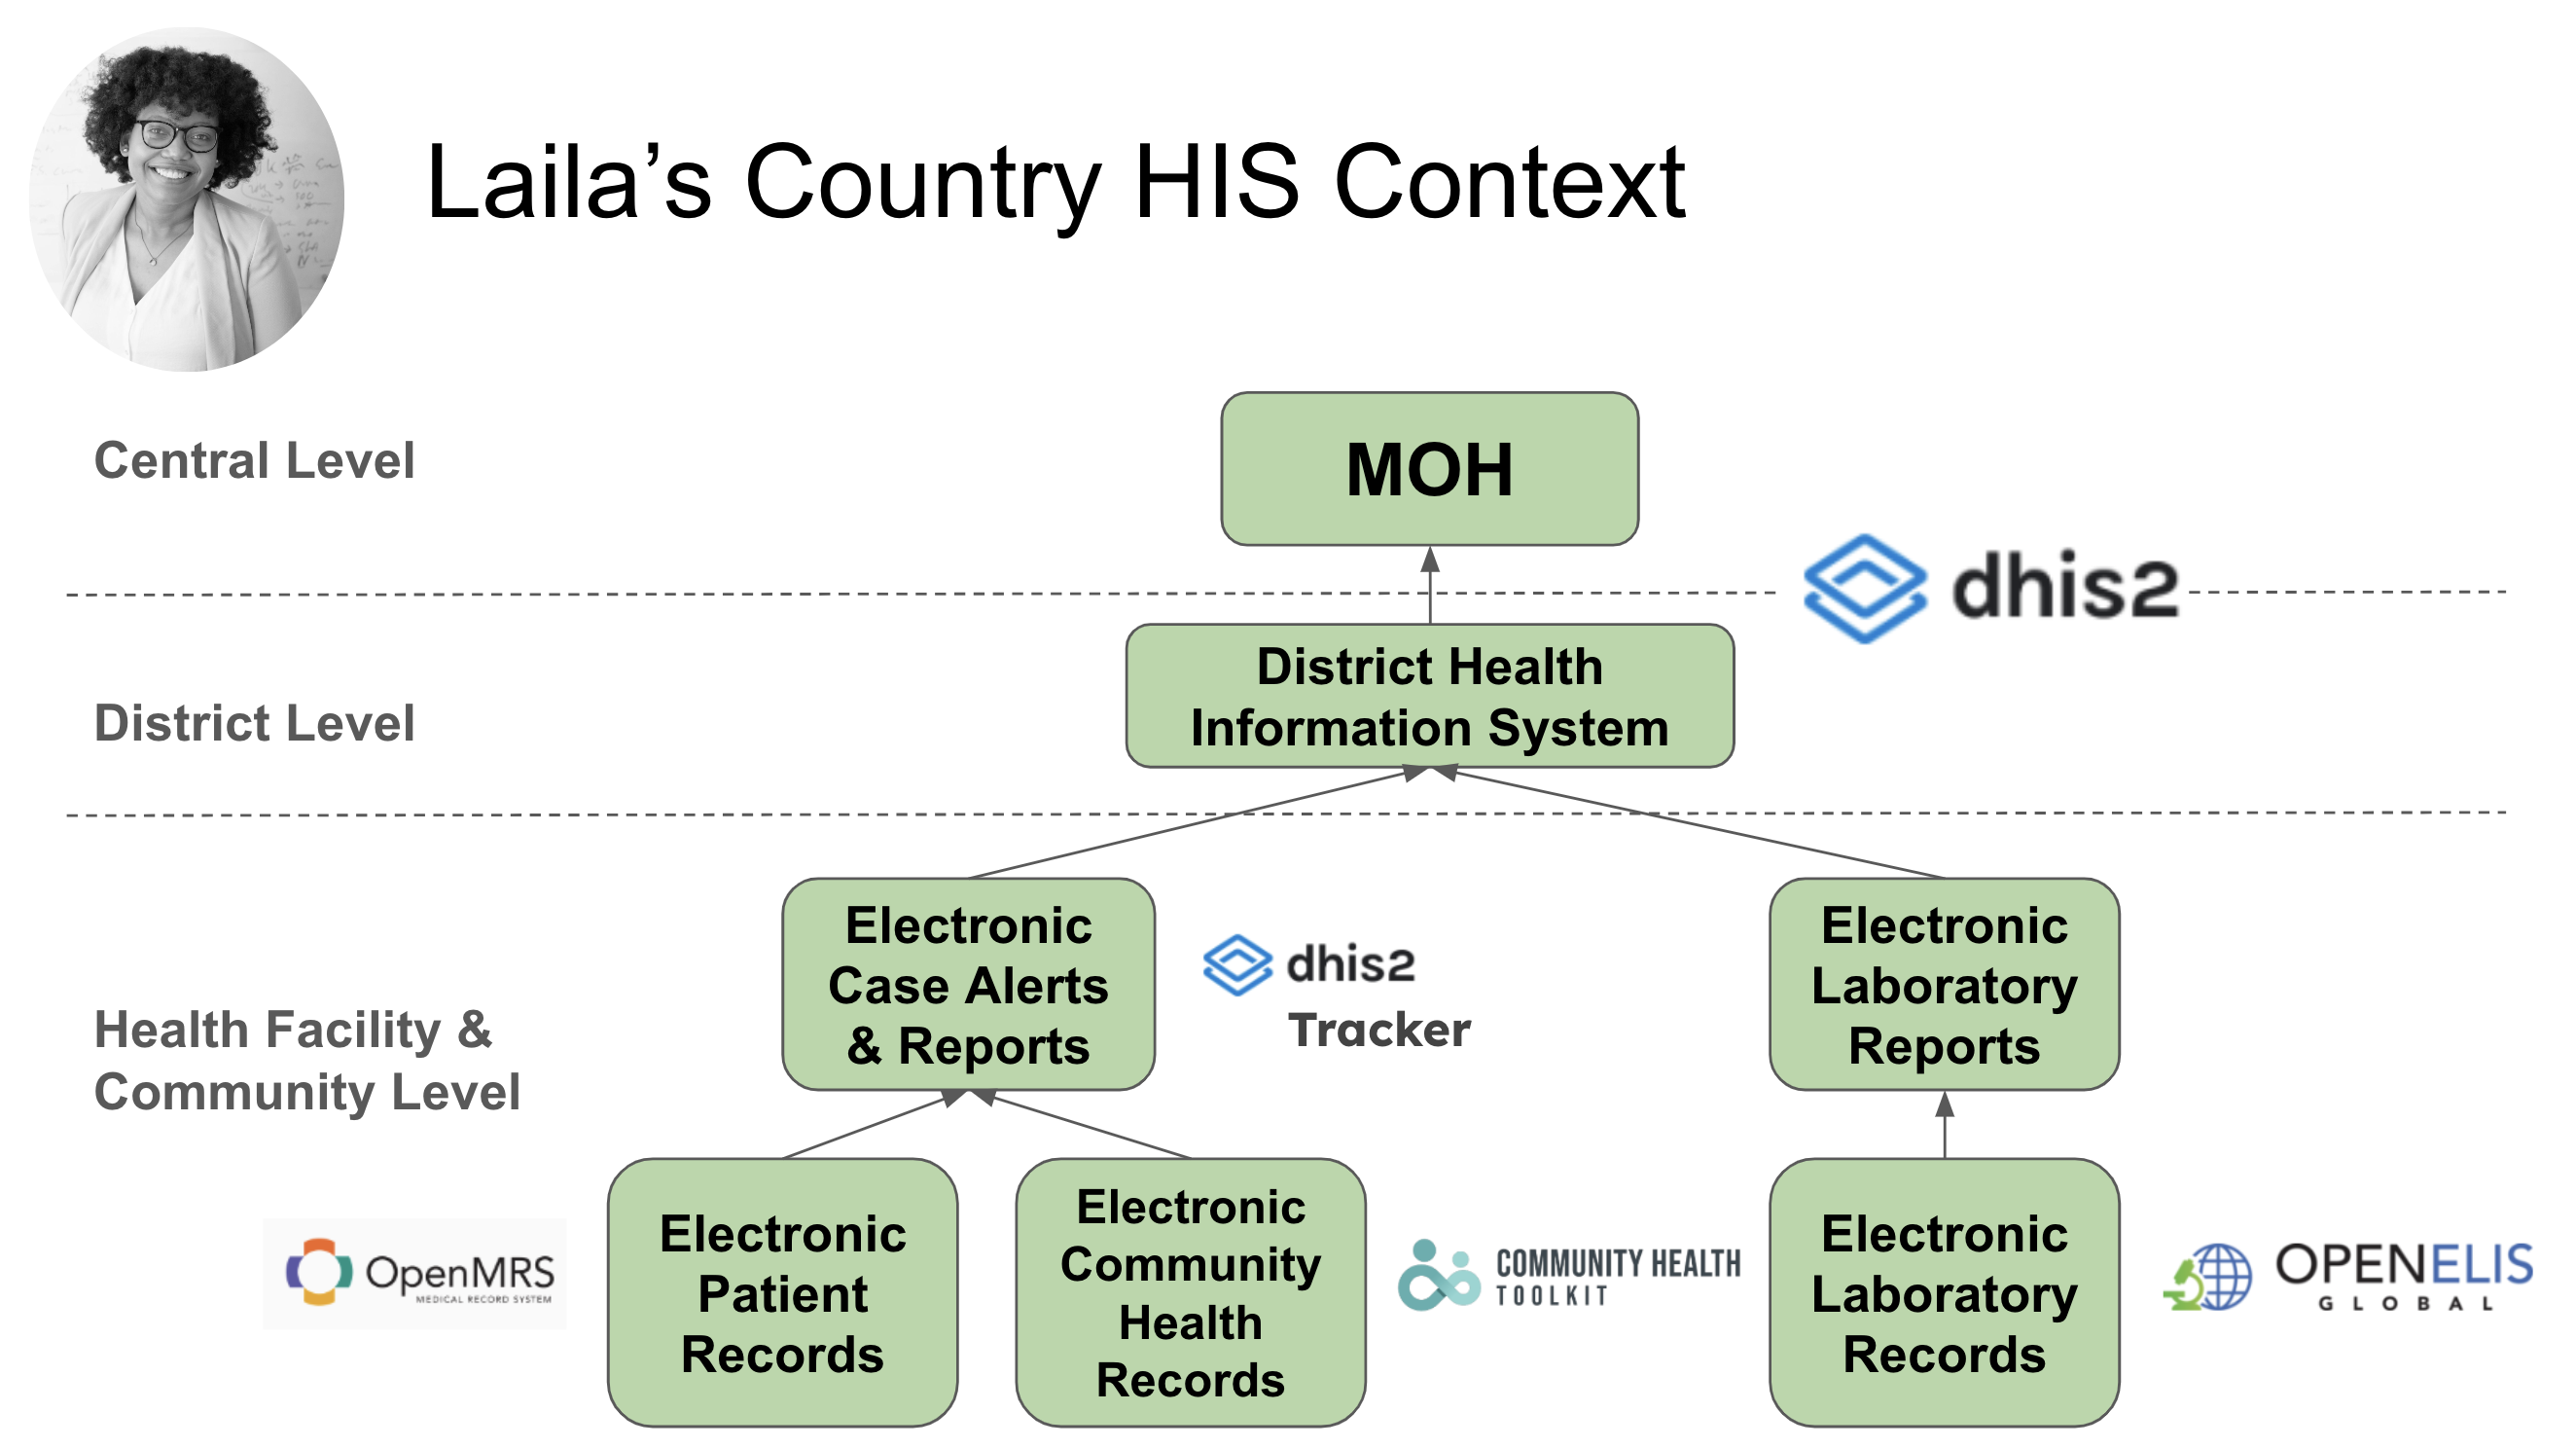

*Follow the case and laboratory reporting branches to the district health information system and Ministry of Health (MOH). Ask who can access each system.*

**Learning objective:** **Trace** a case-report path and a laboratory-report path from source records to MOH.

## Laila's case

Kukuna Health Center calls about reports of fever and rash. Laila's team must prepare a surveillance summary. She needs to know where the data originates, which paper and electronic systems hold it, and who can use each system.

In the diagram above, build two **electronic** paths. For each path, use **Move up** and **Move down** to match the diagram: **MOH at the top, source records at the bottom**. Information travels **upward**, from the bottom of each list to the top. Select a stage first, then move it. Both lists start out of order. Select **Submit** below the lists for feedback on both reporting pathways. You can reorder and submit again; the Learning panel records each attempt. Here, a pathway means the sequence of reporting systems, rather than a geographic map.

Trace the fever-and-rash reporting path shown in the diagram.


In [ ]:
# Run once to display the route controls. Re-running resets both routes.
try:
    import ipywidgets as widgets
except ImportError:
    import piplite
    await piplite.install("ipywidgets==8.1.7")
    import ipywidgets as widgets
from IPython.display import display
from html import escape
from comm import create_comm

def _show_reporting_pathways():
    reporting_state = {"case_moves": 0, "lab_moves": 0}

    case_order = [
        "District health information system",
        "Electronic patient records",
        "Ministry of Health",
        "Electronic case alerts and reports",
    ]
    lab_order = [
        "Electronic laboratory reports",
        "Ministry of Health",
        "Electronic laboratory records",
        "District health information system",
    ]
    case_list = widgets.Select(options=case_order, rows=4, description="", layout=widgets.Layout(width="100%", min_width="0"))
    lab_list = widgets.Select(options=lab_order, rows=4, description="", layout=widgets.Layout(width="100%", min_width="0"))

    def move_stage(stage_list, direction, route_name):
        items = list(stage_list.options)
        selected = stage_list.value
        if selected not in items:
            return
        old = items.index(selected)
        new = old + direction
        if not 0 <= new < len(items):
            return
        items[old], items[new] = items[new], items[old]
        stage_list.options = items
        stage_list.value = selected
        if route_name == "case":
            reporting_state["case_moves"] += 1
        else:
            reporting_state["lab_moves"] += 1
        feedback.value = "Order changed. Select Submit to check your current pathways."

    def route_controls(stage_list, route_name):
        up = widgets.Button(description="Move up", icon="arrow-up")
        down = widgets.Button(description="Move down", icon="arrow-down")
        up.on_click(lambda _: move_stage(stage_list, -1, route_name))
        down.on_click(lambda _: move_stage(stage_list, 1, route_name))
        return widgets.VBox([
            widgets.HTML("<b>Top: central level (MOH)</b>"),
            stage_list,
            widgets.HTML("<b>&uarr; Reporting flows upward from source records at the bottom.</b>"),
            widgets.HBox([up, down]),
        ], layout=widgets.Layout(width="100%", min_width="0"))

    def collect_reporting_pathways():
        return {
            "case": list(reversed(case_list.options)),
            "lab": list(reversed(lab_list.options)),
            "case_moves": reporting_state["case_moves"],
            "lab_moves": reporting_state["lab_moves"],
        }

    submit_button = widgets.Button(description="Submit", button_style="info", disabled=True)
    feedback = widgets.HTML(value="Connecting to your learning record...")
    submitted_pathways = widgets.HTML()
    submission_channel = create_comm(target_name="al.submit", data={"cell": "1"})

    def receive_submission(message):
        data = message["content"]["data"]
        if data.get("ready"):
            feedback.value = "Match the diagram: MOH at the top, source records at the bottom. Reporting flows upward. Then select Submit."
        elif data.get("outcome"):
            outcome = data["outcome"]
            if outcome == "Incomplete":
                feedback.value = "<b>Not complete yet.</b> Move stages in both pathways, then submit again. This attempt was recorded."
            else:
                messages = []
                for key, label in (("case", "Case pathway"), ("lab", "Laboratory pathway")):
                    expected = _expected_case if key == "case" else _expected_lab
                    correct = reporting_pathways[key] == expected
                    messages.append(f"<b>{label}: {'Correct' if correct else 'Incorrect'}.</b> " +
                                    ("Your layout matches the diagram; reports flow upward from source records to MOH." if correct else
                                     "Read upward: source records at the bottom, then reports, then the district system, with MOH at the top."))
                feedback.value = "<br>".join(messages) + "<br>Attempt recorded. See the Learning panel for your next suggestion."
        else:
            feedback.value = escape(data.get("error", "Could not record. Please try again."))
        submit_button.disabled = False
        for control in pathway_controls:
            control.disabled = False

    submission_channel.on_msg(receive_submission)

    def submit_reporting_pathways(_=None):
        global reporting_pathways
        reporting_pathways = collect_reporting_pathways()
        submitted_pathways.value = "<b>Submitted reporting flow</b><p>Read these arrows left to right: source records &rarr; reports &rarr; district &rarr; MOH. This is the upward flow in your lists and in the diagram.</p>" + "".join(
            "<p><b>" + label + ":</b> " + " &rarr; ".join(escape(stage) for stage in reporting_pathways[key]) + "</p>"
            for key, label in (("case", "Case pathway"), ("lab", "Laboratory pathway")))
        submit_button.disabled = True
        for control in pathway_controls:
            control.disabled = True
        feedback.value = "Checking and recording this attempt..."
        submission_channel.send({"submit": True})

    submit_button.on_click(submit_reporting_pathways)
    _expected_case = ['Electronic patient records', 'Electronic case alerts and reports', 'District health information system', 'Ministry of Health']
    _expected_lab = ['Electronic laboratory records', 'Electronic laboratory reports', 'District health information system', 'Ministry of Health']
    case_controls = route_controls(case_list, "case")
    lab_controls = route_controls(lab_list, "lab")
    pathway_controls = [case_list, lab_list, *case_controls.children[3].children, *lab_controls.children[3].children]
    display(widgets.VBox([
        widgets.HTML("<b>1. Health facility case-report path</b>"),
        case_controls,
        widgets.HTML("<b>2. Laboratory-report path</b>"),
        lab_controls,
        submit_button, submitted_pathways, feedback,
    ]))

_show_reporting_pathways()


Select **Submit** above to check your current reporting pathways. Keep MOH at the top and source records at the bottom, as in the diagram. Feedback shows the upward reporting flow and whether each pathway is correct. Reorder and submit again to retry.

## Reflect on system use

Run the next cell to enter your reflections. Select **Record** to save them in this browser. Your responses are unscored.

In [ ]:
# Run this cell to write and record your reflections.
try:
    import ipywidgets as widgets
except ImportError:
    import piplite
    await piplite.install("ipywidgets==8.1.7")
    import ipywidgets as widgets
from html import escape
from IPython.display import display
from comm import create_comm

def _reflection_section(section, questions):
    prompts = [question["prompt"] for question in questions]
    fields = []
    for number, prompt in enumerate(prompts, 1):
        field = widgets.Textarea(placeholder="Write your reflection here", rows=5,
                                 layout=widgets.Layout(width="100%"))
        fields.append(field)
        display(widgets.VBox([
            widgets.HTML(value=f"<strong>{number}. {escape(prompt)}</strong>"), field
        ], layout=widgets.Layout(width="100%", padding="0.5rem", margin="0 0 0.5rem 0")))
    button = widgets.Button(description="Record", button_style="info", disabled=True)
    status = widgets.HTML(value="Connecting to your browser learner record...")
    status.add_class("course-reflection-status")
    channel = create_comm(target_name="al.reflections", data={"section": section})
    def receive(message):
        data = message["content"]["data"]
        if "entries" in data:
            entries = data["entries"]
            restored = 0
            earlier = 0
            for question, field in zip(questions, fields):
                saved = next((entry for entry in reversed(entries) if
                    (entry.get("id") == question["id"] and entry.get("version") == question["version"]) or
                    (question["version"] == 1 and not entry.get("id") and entry["prompt"] in question["legacyPrompts"])), None)
                field.value = saved["answer"] if saved else ""
                restored += saved is not None
                earlier += any(entry.get("id") == question["id"] and entry.get("version") != question["version"] for entry in entries)
            status.value = "Recorded reflections restored." if restored else "Select Record to save in this browser."
            if earlier or any(entry.get("history") for entry in entries) or len(entries) > restored:
                status.value += " Earlier responses remain in My learning record and Download reflections. Review them before answering revised questions."
        elif data.get("saved"):
            status.value = "Recorded in this browser. Your reflections are unscored."
        else:
            status.value = escape(data.get("error", "Could not record. Please try again."))
        button.disabled = False
    channel.on_msg(receive)
    def record(_):
        button.disabled = True
        status.value = "Recording..."
        channel.send({"entries": [{**question, "answer": field.value}
                                  for question, field in zip(questions, fields)]})
    def edited(_):
        status.value = "Changes not recorded. Select Record to save."
    for field in fields:
        field.observe(edited, names="value")
    button.on_click(record)
    display(button, status)

_reflection_section('exercise:u02-n01', [{'id': 'q-55d65b433504', 'version': 1, 'prompt': 'Who needs each case or laboratory report?', 'legacyPrompts': ['Who needs each case or laboratory report?']}, {'id': 'q-1767b9fc9c5d', 'version': 1, 'prompt': 'What access question would you verify with the district team?', 'legacyPrompts': ['What access question would you verify with the district team?']}])


## Continue the case

Use the **Learning** panel for the next activity. If a route was incorrect,
follow each arrow in the diagram and submit your revised reporting pathways.


## References

- UCSF-IGHS, *FETP JupyterBook*, Unit 2 HIS case study and group work; adapted with a local system map.
- [Unit 2 course slides (local PDF)](../../readings/ucsf/assets/unit-2-version-2-slides.pdf).
